# Phantom Fairness: auditing fairness against automatically extracted labels

### Part 3 of 4 - Instance dependence of the label noise, the noise-injection experiment, mitigation and robustness

**Revision 2 (response to reviewers).**

| Change | Reviewer comment |
|---|---|
| Instance dependence is tested with three patient-aware methods in addition to the original image-level Mann-Whitney test: a patient-level bootstrap of the rank-biserial correlation, within-cluster resampling (one image per patient per draw), and GEE logistic models with an exchangeable within-patient correlation, unadjusted and adjusted for sex, age band and projection. | R4.1 |
| The test is run on four backbones, including the CheXpert-only DenseNet-121 that never saw NIH data. Part 4 adds scores that were never trained against the NLP labels at all. | R4.2, R4.3 |
| The injection experiment gains a **calibrated arm** whose injected misses have the same measured association with the model score as the real NLP misses (between the random arm and the limiting hardest-case arm). | R4.5 |
| The whole injection is repeated inside a **patient-level bootstrap** (flip rates re-estimated in every replicate), and in a **sample-split** design where flip rates are estimated on one half of the patients and the prediction is tested on the other half. The three kinds of evidence (observed association, mechanistic illustration, out-of-sample generalisation) are tabulated separately. | R4.5 |
| Mitigation results carry intervals across the 25 patient splits. | R1.3 |

The original point estimates (Table 4 of the submission) are reproduced with the original functions and seeds, so they can be compared directly.

---
## 0. Setup and rehydration from the caches

In [1]:
import sys, os, json, time
from pathlib import Path
# phantom_core.py must sit in the same folder as the notebooks.
for _p in (Path.cwd(), Path.cwd() / "notebooks"):
    if (_p / "phantom_core.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import phantom_core as pc

CFG = pc.Config()
# Manuscript-run settings are the defaults in phantom_core.Config.
# Set the environment variable PF_QUICK=1 for a fast dry run (small resample counts).
if os.environ.get("PF_QUICK"):
    CFG.n_bootstrap, CFG.n_wcr, CFG.n_inject_mc = 200, 100, 30
    CFG.n_inject_boot, CFG.n_inject_boot_mc, CFG.n_crossfit_splits = 30, 5, 20
VERSIONS = pc.setup_runtime(CFG)
TIMES = pc.Timings(CFG, "part3")
log = pc.log
ARCHIVE = pc.archive_v1_outputs(CFG)
print("Project folder:", CFG.out)
print("Original-submission tables archived at:", ARCHIVE)
print(json.dumps(VERSIONS, indent=2))

Project folder: C:\Users\kruta\Downloads\phantom-fairness-revision2\phantom-fairness-main\notebooks\phantom_fairness
Original-submission tables archived at: C:\Users\kruta\Downloads\phantom-fairness-revision2\phantom-fairness-main\notebooks\phantom_fairness\tables\v1_original
{
  "python": "3.11.15",
  "numpy": "2.4.4",
  "pandas": "3.0.3",
  "matplotlib": "3.11.0",
  "platform": "Windows-10-10.0.26300-SP0",
  "sklearn": "1.9.0",
  "scipy": "1.17.1",
  "statsmodels": "0.14.6",
  "torch": "2.12.1+cpu",
  "torchvision": "0.27.1+cpu",
  "torchxrayvision": "1.4.0",
  "open_clip": "3.3.0"
}


In [2]:
with TIMES.track("load_masters_and_cohort"):
    nih_master, padchest_master, ADJ_AUDIT = pc.load_masters(CFG)
    train_df, val_df, test_df, eval_clean = pc.build_cohort(CFG, nih_master)
FRAMES = {"train": train_df, "val": val_df, "evalclean": eval_clean}
NLP_FINDINGS = pc.nlp_findings(CFG)          # Fracture has no NLP label and is handled separately
AXES = pc.SUBGROUP_AXES
CHECK = pc.check_cohort_against_cache(CFG, FRAMES)
if len(CHECK):
    display(CHECK)
    bad = CHECK[~CHECK["match"]]
    if len(bad) and not CFG.allow_reextract:
        raise RuntimeError("The rebuilt cohort does not match the cached embeddings listed above. "
                           "Do not continue: the numbers would not correspond to the original run.")
print(f"train {len(train_df)} | val {len(val_df)} | held-out {len(test_df)} | evaluation {len(eval_clean)} images, "
      f"{eval_clean['patient_id'].nunique()} patients")

21:33:25 [INFO] Loaded master_nih_v2 from cache: 112120 rows


,split,manifest,n,match
0,train,train__clip_vitb32__manifest.json,20000,True
1,train,train__resnet50_imagenet__manifest.json,20000,True
2,train,train__xrv_densenet121__manifest.json,20000,True
3,train,train__xrv_densenet121_chex__manifest.json,20000,True
4,val,val__clip_vitb32__manifest.json,12930,True
5,val,val__resnet50_imagenet__manifest.json,12930,True
6,val,val__xrv_densenet121__manifest.json,12930,True
7,val,val__xrv_densenet121_chex__manifest.json,12930,True
8,evalclean,evalclean__clip_vitb32__manifest.json,4376,True
9,evalclean,evalclean__resnet50_imagenet__manifest.json,4376,True


train 20000 | val 12930 | held-out 26921 | evaluation 4376 images, 1695 patients


In [3]:
EMB, MODELS, EVALS = {}, {}, {}
for bb in CFG.embedding_backbones:
    if bb == "xrv_densenet121_chex" and not CFG.chex_full_pipeline:
        continue
    try:
        with TIMES.track(f"load_embeddings_{bb}"):
            EMB[bb] = pc.embed_frames(CFG, bb, FRAMES)
        if EMB[bb]["train"][0] is None:
            print(f"{bb}: no embeddings; skipped"); continue
        MODELS[bb] = pc.train_heads(EMB[bb], NLP_FINDINGS, C=CFG.head_C)
        EVALS[bb] = pc.filter_eval_groups(pc.build_eval_scores(MODELS[bb], bb), AXES, CFG.min_group_n)
    except RuntimeError:
        raise
    except Exception as e:
        log.warning("Backbone %s unavailable: %s", bb, e)
P = CFG.primary_backbone
EVAL = EVALS[P]
print("Backbones ready:", list(EVALS.keys()), "| evaluation images:", len(EVAL))
print("Primary thresholds:", {k: round(v, 3) for k, v in MODELS[P]["thresholds"].items()})

Backbones ready: ['xrv_densenet121', 'resnet50_imagenet', 'clip_vitb32', 'xrv_densenet121_chex'] | evaluation images: 4375
Primary thresholds: {'Airspace opacity': 0.474, 'Pneumothorax': 0.084, 'Nodule or mass': 0.537}


In [4]:
# Measured subgroup flip rates on the evaluation set (as in the submission)
def measure_group_noise(ev, finding, axis):
    nlp, adj = "nlp_" + finding, "adj_" + finding
    sub = ev[ev[adj].notna()]; out = {}
    for g, grp in sub.groupby(axis):
        ya, yn = grp[adj].astype(int).values, grp[nlp].astype(int).values
        pos, neg = ya == 1, ya == 0
        out[str(g)] = {"eps_plus": float((yn[pos] == 0).mean()) if pos.sum() else np.nan,
                       "eps_minus": float((yn[neg] == 1).mean()) if neg.sum() else np.nan,
                       "pi": float(pos.mean()) if len(ya) else np.nan, "n": int(len(grp))}
    return out
MEASURED_NOISE = {(f, ax): measure_group_noise(EVAL, f, ax) for f in NLP_FINDINGS for ax in AXES}

---
## 1. Exploratory second dataset (PadChest sample, unchanged)

The 24-image PadChest sample only confirms that the pipeline runs on a second dataset. It is far too small for inference, and the primary backbone was pretrained on PadChest. It should be listed as a limitation (R3).

In [5]:
def bootstrap_gap_ci_legacy(df, gc, score, label, thr, metric, n_boot=2000, seed=0, alpha=0.05):
    r = np.random.default_rng(seed); idxg = {g: s.index.values for g, s in df.groupby(gc)}
    point = pc.gap_from_groups(pc.group_values(df, gc, score, label, thr, metric)); boots = []
    for _ in range(n_boot):
        bs = pd.concat([df.loc[r.choice(ix, len(ix), True)] for ix in idxg.values()])
        g = pc.gap_from_groups(pc.group_values(bs, gc, score, label, thr, metric))
        if not np.isnan(g): boots.append(g)
    if not boots: return point, np.nan, np.nan, 0
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)]); return point, float(lo), float(hi), len(boots)

PC = None
if len(padchest_master):
    try:
        try:
            e, _ = pc.extract_embeddings(CFG, "padchest", padchest_master, "ImageID", P)
        except RuntimeError:
            e, _ = pc.extract_embeddings(CFG, "padchest", padchest_master, "ImageID", P, force=True)
        if e is not None:
            Z = MODELS[P]["scaler"].transform(e); PC = padchest_master.copy()
            for f, clf in MODELS[P]["heads"].items(): PC["score_" + f] = clf.predict_proba(Z)[:, 1]
    except Exception as ex:
        log.warning("PadChest scoring skipped: %s", ex)
if PC is not None:
    rows = []
    for f in NLP_FINDINGS:
        y, p = PC["pc_" + f].astype(int).values, PC["score_" + f].values
        if len(np.unique(y)) > 1:
            a, lo, hi = pc.auc_ci_delong(y, p); rows.append({"finding": f, "n": len(PC), "pos": int(y.sum()), "AUROC_padchest": a, "lo": lo, "hi": hi})
        else:
            rows.append({"finding": f, "n": len(PC), "pos": int(y.sum()), "AUROC_padchest": np.nan, "lo": np.nan, "hi": np.nan})
    pd.DataFrame(rows).to_csv(CFG.tab_dir / "table8_padchest_discrimination.csv", index=False); display(pd.DataFrame(rows).round(3))
else:
    print("PadChest sample not available; section skipped.")

,finding,n,pos,AUROC_padchest,lo,hi
0,Airspace opacity,24,5,0.489,0.243,0.736
1,Pneumothorax,24,0,NaN,NaN,NaN
2,Nodule or mass,24,1,0.609,0.405,0.813


---
## 2. Instance dependence of the NLP labelling noise (primary analysis)

Among images that the reference standard calls positive, are those the NLP labels missed scored lower by the model than those the NLP labels caught? Rank-biserial r = 2·AUC(caught versus missed) − 1; positive r means missed positives score lower.

Because positives cluster within patients, four tests are reported. The **patient-level bootstrap** and **within-cluster resampling** answer the reviewer's request directly; the **GEE** models add a check that the association is not explained by subgroup composition (adjusted for sex, age band and projection). Benjamini-Hochberg adjustment is applied separately to each p-value type across all backbone-by-finding tests.

Interpretation (R4.2): all heads here were trained on NLP labels, so this section shows that *models trained on NLP labels* give NLP-missed positives lower scores. Part 4 repeats the test with scores that never saw the NLP labels.

In [6]:
ID = []
for bb, ev in EVALS.items():
    with TIMES.track(f"instance_dependence_{bb}"):
        t = pc.instance_dependence_table(ev, NLP_FINDINGS, CFG, label=bb)
    t.insert(1, "exposure", pc.BACKBONE_EXPOSURE[bb]["status"]); ID.append(t)
ID = pc.add_bh(pd.concat(ID, ignore_index=True))
ID.to_csv(CFG.tab_dir / "table10b_instance_dependence_backbones.csv", index=False)
ID[ID["score_source"] == P].to_csv(CFG.tab_dir / "table10a_instance_dependence.csv", index=False)
cols = ["score_source", "finding", "n_missed", "n_caught", "n_patients_pos", "rank_biserial", "r_lo_patient", "r_hi_patient",
        "p_image_mwu_bh", "p_patient_boot_bh", "r_wcr", "p_wcr_bh", "gee_or_per_sd_lower", "p_gee_bh",
        "gee_adj_or_per_sd_lower", "gee_adj_or_lo", "gee_adj_or_hi", "p_gee_adj_bh"]
display(ID[[c for c in cols if c in ID.columns]].round(4))
for col in ("p_image_mwu_bh", "p_patient_boot_bh", "p_wcr_bh", "p_gee_bh", "p_gee_adj_bh"):
    if col in ID.columns:
        print(f"{col:20s}: {int((ID[col] < 0.05).sum())} of {ID[col].notna().sum()} tests < 0.05 (max {ID[col].max():.3g})")
print("Median r by backbone:", ID.groupby("score_source")["rank_biserial"].median().round(3).to_dict())

,score_source,finding,n_missed,n_caught,n_patients_pos,rank_biserial,r_lo_patient,r_hi_patient,p_image_mwu_bh,p_patient_boot_bh,r_wcr,p_wcr_bh,gee_or_per_sd_lower,p_gee_bh,gee_adj_or_per_sd_lower,gee_adj_or_lo,gee_adj_or_hi,p_gee_adj_bh
0,xrv_densenet121,Airspace opacity,1280,886,820,0.2017,0.1494,0.2555,0.0000,0.0005,0.2074,0.0000,1.3943,0.0000,1.3501,1.2244,1.4887,0.0000
1,xrv_densenet121,Pneumothorax,129,109,154,0.1654,0.0348,0.2983,0.0199,0.0117,0.2076,0.0102,1.3726,0.0074,1.3003,1.0011,1.6891,0.0368
2,xrv_densenet121,Nodule or mass,349,256,346,0.2401,0.1328,0.3478,0.0000,0.0005,0.2543,0.0000,1.5086,0.0000,1.4719,1.2210,1.7744,0.0001
3,resnet50_imagenet,Airspace opacity,1280,886,820,0.1602,0.1073,0.2097,0.0000,0.0005,0.1805,0.0000,1.2602,0.0000,1.2247,1.1135,1.3470,0.0000
4,resnet50_imagenet,Pneumothorax,129,109,154,0.1604,0.0022,0.3199,0.0199,0.0293,0.1164,0.1069,1.1728,0.1069,1.1203,0.8522,1.4728,0.2134
5,resnet50_imagenet,Nodule or mass,349,256,346,0.1678,0.0589,0.2787,0.0004,0.0021,0.1824,0.0011,1.3172,0.0060,1.3002,1.0596,1.5953,0.0102
6,clip_vitb32,Airspace opacity,1280,886,820,0.1718,0.1201,0.2237,0.0000,0.0005,0.1978,0.0000,1.3153,0.0000,1.2687,1.1562,1.3922,0.0000
7,clip_vitb32,Pneumothorax,129,109,154,0.1333,-0.0268,0.2871,0.0383,0.0492,0.1244,0.1020,1.2692,0.0542,1.1246,0.8418,1.5024,0.2134
8,clip_vitb32,Nodule or mass,349,256,346,0.1515,0.0490,0.2604,0.0012,0.0020,0.1364,0.0143,1.3051,0.0039,1.2717,1.0561,1.5313,0.0102
9,xrv_densenet121_chex,Airspace opacity,1280,886,820,0.1941,0.1381,0.2494,0.0000,0.0005,0.2145,0.0000,1.3746,0.0000,1.3242,1.1897,1.4738,0.0000


p_image_mwu_bh      : 12 of 12 tests < 0.05 (max 0.0383)
p_patient_boot_bh   : 12 of 12 tests < 0.05 (max 0.0492)
p_wcr_bh            : 8 of 12 tests < 0.05 (max 0.143)
p_gee_bh            : 9 of 12 tests < 0.05 (max 0.107)
p_gee_adj_bh        : 8 of 12 tests < 0.05 (max 0.213)
Median r by backbone: {'clip_vitb32': 0.152, 'resnet50_imagenet': 0.16, 'xrv_densenet121': 0.202, 'xrv_densenet121_chex': 0.134}


In [7]:
# Comparison with the original submission (image-level p across nine tests)
v1p = CFG.tab_dir / "v1_original" / "table10b_instance_dependence_backbones.csv"
if v1p.exists():
    v1 = pd.read_csv(v1p).rename(columns={"backbone": "score_source", "rank_biserial": "v1_rank_biserial", "p_adj": "v1_p_adj_image"})
    cmp = ID.merge(v1[["score_source", "finding", "v1_rank_biserial", "v1_p_adj_image"]], on=["score_source", "finding"], how="left")
    cmp = cmp[["score_source", "finding", "v1_rank_biserial", "rank_biserial", "v1_p_adj_image", "p_image_mwu_bh",
               "r_lo_patient", "r_hi_patient", "p_patient_boot_bh", "p_wcr_bh", "p_gee_adj_bh"]]
    cmp.to_csv(CFG.tab_dir / "table10b_v1_vs_v2_comparison.csv", index=False); display(cmp.round(4))

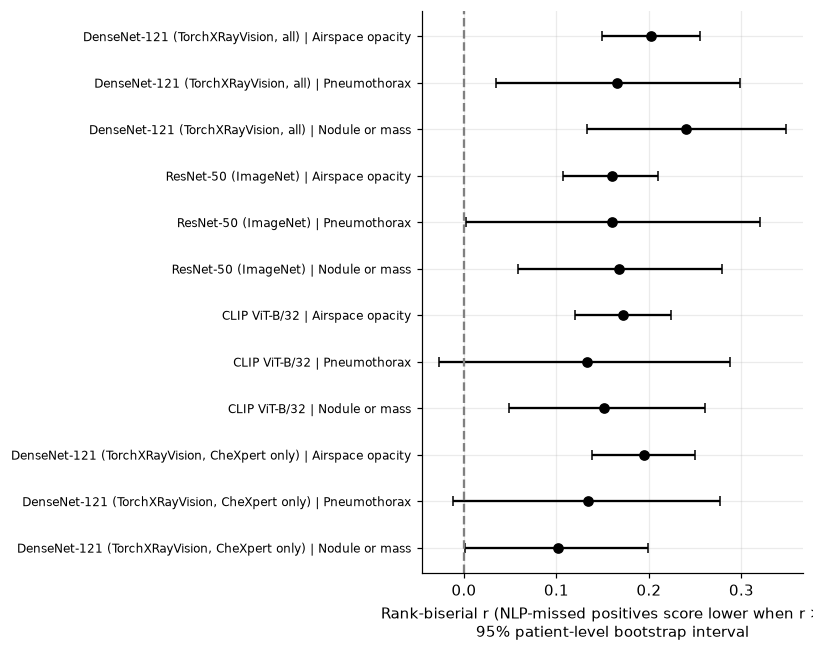

In [8]:
# Forest plot of r with patient-level intervals
d = ID.copy(); d["lab"] = d["score_source"].map(pc.BACKBONE_LABELS).fillna(d["score_source"]) + " | " + d["finding"]
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(d) + 1))
yy = np.arange(len(d))[::-1]
ax.errorbar(d["rank_biserial"], yy, xerr=[(d["rank_biserial"] - d["r_lo_patient"]).clip(lower=0), (d["r_hi_patient"] - d["rank_biserial"]).clip(lower=0)],
            fmt="o", color="k", capsize=3)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(yy); ax.set_yticklabels(d["lab"], fontsize=8)
ax.set_xlabel("Rank-biserial r (NLP-missed positives score lower when r > 0)\n95% patient-level bootstrap interval")
plt.savefig(CFG.fig_dir / "fig_instance_dependence_forest.png", bbox_inches="tight"); plt.show()

---
## 3. Noise-injection experiment

Starting from the reference-standard labels of the evaluation images, the measured subgroup flip rates are injected in three ways and the audited TPR gap is recomputed. Concealment = true gap (reference standard) − audited gap; positive means the audit understates the disparity.

* **Random (class-conditional):** each label flips independently at the subgroup's measured rate (original arm).
* **Hardest-case (limiting instance-dependent case):** the same number of positives is removed by taking those with the lowest model scores (original arm).
* **Calibrated (measured instance dependence; new):** the same number of positives is removed, sampled with probability decreasing in the within-subgroup score percentile, with the strength chosen so the injected misses reproduce the rank-biserial correlation measured for the real NLP misses.

All arms add false positives at random at the measured rate. 3a reproduces the submission's point estimates exactly and adds the calibrated arm; 3b propagates the uncertainty of estimating the flip rates from the same sample; 3c estimates the rates on one half of the patients and tests on the other.

In [9]:
# 3a. Point estimates: original functions and seeds (reproduce the submission), plus the calibrated arm
def _tpr_gap(ev_sub, axis, sc, ylab_array, thr):
    df = ev_sub.copy(); df["_y"] = ylab_array; tp = {}
    for g, s in df.groupby(axis):
        y = s["_y"].astype(int).values; yhat = (s[sc].values >= thr).astype(int); tp[str(g)] = pc.tpr_fpr(y, yhat)[0]
    return pc.gap_from_groups(tp)

def inject_group_noise(y, groups, eps_plus, eps_minus, rng):
    y = np.asarray(y).astype(int).copy(); groups = np.asarray(groups).astype(str)
    for g in np.unique(groups):
        ix = np.where(groups == g)[0]; ep = eps_plus.get(g, 0.0); em = eps_minus.get(g, 0.0)
        ep = 0.0 if (ep is None or np.isnan(ep)) else min(float(ep), 1.0); em = 0.0 if (em is None or np.isnan(em)) else min(float(em), 1.0)
        pos = ix[y[ix] == 1]; neg = ix[y[ix] == 0]
        if len(pos): y[pos[rng.random(len(pos)) < ep]] = 0
        if len(neg): y[neg[rng.random(len(neg)) < em]] = 1
    return y

def inject_classcond(y, groups, score, ep, em, rng):
    return inject_group_noise(y, groups, ep, em, rng)

def inject_instancedep(y, groups, score, ep, em, rng):
    y = np.asarray(y).astype(int).copy(); groups = np.asarray(groups).astype(str); score = np.asarray(score, float)
    for g in np.unique(groups):
        e1 = ep.get(g, 0.0) or 0.0; e0 = em.get(g, 0.0) or 0.0
        e1 = min(float(0 if np.isnan(e1) else e1), 1.0); e0 = min(float(0 if np.isnan(e0) else e0), 1.0)
        gpos = np.where((groups == g) & (y == 1))[0]; gneg = np.where((groups == g) & (y == 0))[0]
        if len(gpos):
            ndrop = int(round(e1 * len(gpos))); order = gpos[np.argsort(score[gpos])]; y[order[:ndrop]] = 0
        if len(gneg): y[gneg[rng.random(len(gneg)) < e0]] = 1
    return y

def phantom_decomposition(ev, finding, axis, lam=1.0, n_mc=None, seed=0):
    n_mc = n_mc or CFG.n_inject_mc
    adj, nlp, sc = "adj_" + finding, "nlp_" + finding, "score_" + finding
    thr = MODELS[P]["thresholds"].get(finding, 0.5)
    sub = ev[ev[adj].notna()].copy()
    if sub[axis].nunique() < 2: return None
    y = sub[adj].astype(int).values; grp = sub[axis].astype(str).values; score = sub[sc].values
    noise = MEASURED_NOISE.get((finding, axis), {})
    ep = {g: (noise.get(g, {}).get("eps_plus", 0.0) or 0.0) * lam for g in noise}
    em = {g: (noise.get(g, {}).get("eps_minus", 0.0) or 0.0) * lam for g in noise}
    clean_gap = _tpr_gap(sub, axis, sc, y, thr); obs_nlp_gap = _tpr_gap(sub, axis, sc, sub[nlp].astype(int).values, thr)
    r = np.random.default_rng(seed); cc, idp = [], []
    for _ in range(n_mc):
        g1 = _tpr_gap(sub, axis, sc, inject_classcond(y, grp, score, ep, em, r), thr)
        if not np.isnan(g1): cc.append(g1)
        g2 = _tpr_gap(sub, axis, sc, inject_instancedep(y, grp, score, ep, em, r), thr)
        if not np.isnan(g2): idp.append(g2)
    gcc = float(np.mean(cc)) if cc else np.nan; gid = float(np.mean(idp)) if idp else np.nan
    return {"finding": finding, "axis": axis, "clean_gap": clean_gap, "observed_nlp_gap": obs_nlp_gap,
            "gap_classcond": gcc, "gap_instancedep": gid, "phantom_observed": clean_gap - obs_nlp_gap,
            "phantom_classcond": clean_gap - gcc, "phantom_instancedep": clean_gap - gid}

CELLS_FA = [(f, ax) for f in NLP_FINDINGS for ax in ["sex", "elderly_women"]]
INJ = EVAL.dropna(subset=["adj_" + f for f in NLP_FINDINGS]).reset_index(drop=True)
def cell_arrays(f, ax, frame=INJ, bb=P):
    return {"finding": f, "axis": ax, "y_adj": frame["adj_" + f].astype(int).values, "y_nlp": frame["nlp_" + f].astype(int).values,
            "score": frame["score_" + f].values, "groups": frame[ax].astype(str).values, "thr": MODELS[bb]["thresholds"][f]}
CELLS = [cell_arrays(f, ax) for f, ax in CELLS_FA]

with TIMES.track("injection_point"):
    DEC = pd.DataFrame([phantom_decomposition(EVAL, f, ax) for f, ax in CELLS_FA])
    cal = []
    for c in CELLS:
        r = pc.injection_cell(c["y_adj"], c["y_nlp"], c["score"], c["groups"], c["thr"], n_mc=CFG.n_inject_mc, seed=0)
        cal.append({"finding": c["finding"], "axis": c["axis"], "phantom_calibrated": r["conceal_calibrated"],
                    "calibration_target_r": r["target_r"], "calibration_beta": r["beta"]})
    DEC = DEC.merge(pd.DataFrame(cal), on=["finding", "axis"])
DEC.to_csv(CFG.tab_dir / "table10_phantom_decomposition.csv", index=False)
display(DEC[["finding", "axis", "clean_gap", "observed_nlp_gap", "phantom_observed", "phantom_classcond", "phantom_instancedep",
             "phantom_calibrated", "calibration_target_r"]].round(3))
for arm in ("classcond", "instancedep", "calibrated"):
    print(f"mean |observed - {arm}| over six cells: {np.mean(np.abs(DEC['phantom_observed'] - DEC['phantom_' + arm])):.3f}")

,finding,axis,clean_gap,observed_nlp_gap,phantom_observed,phantom_classcond,phantom_instancedep,phantom_calibrated,calibration_target_r
0,Airspace opacity,sex,0.010,0.020,-0.010,-0.017,-0.012,-0.010,0.202
1,Airspace opacity,elderly_women,0.014,0.053,-0.039,-0.022,-0.039,-0.025,0.202
2,Pneumothorax,sex,0.124,0.122,0.002,0.029,0.081,0.037,0.165
3,Pneumothorax,elderly_women,0.184,0.064,0.120,0.077,0.124,0.087,0.165
4,Nodule or mass,sex,0.019,0.064,-0.046,-0.016,-0.014,-0.014,0.240
5,Nodule or mass,elderly_women,0.169,0.120,0.049,0.057,0.054,0.052,0.240


mean |observed - classcond| over six cells: 0.022
mean |observed - instancedep| over six cells: 0.020
mean |observed - calibrated| over six cells: 0.019


In [10]:
# 3b. Patient-level bootstrap of the whole injection (flip rates, target r and calibration re-estimated per replicate)
with TIMES.track("injection_bootstrap"):
    BOOT = pc.injection_bootstrap(CELLS, INJ["patient_id"].values, n_boot=CFG.n_inject_boot, n_mc=CFG.n_inject_boot_mc, seed=CFG.random_seed)
BOOT.to_csv(CFG.tab_dir / "table10c_injection_bootstrap_replicates.csv", index=False)
def _ci(x): return pd.Series({"lo": np.nanpercentile(x, 2.5), "hi": np.nanpercentile(x, 97.5)})
rows = []
for (f, ax), d in BOOT.groupby(["finding", "axis"], sort=False):
    rec = {"finding": f, "axis": ax, "n_replicates": len(d)}
    for k in ("observed", "random", "hardest", "calibrated"):
        v = d["conceal_" + k].values; rec[f"{k}_lo"], rec[f"{k}_hi"] = np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)
    for k in ("random", "hardest", "calibrated"):
        dv = d["conceal_observed"].values - d["conceal_" + k].values
        rec[f"obs_minus_{k}_lo"], rec[f"obs_minus_{k}_hi"] = np.nanpercentile(dv, 2.5), np.nanpercentile(dv, 97.5)
    rec["P(observed concealment > 0)"] = float(np.mean(d["conceal_observed"] > 0))
    rows.append(rec)
BOOTSUM = DEC[["finding", "axis", "phantom_observed", "phantom_classcond", "phantom_instancedep", "phantom_calibrated"]].merge(
    pd.DataFrame(rows), on=["finding", "axis"])
BOOTSUM.to_csv(CFG.tab_dir / "table10c_injection_bootstrap_summary.csv", index=False)
display(BOOTSUM.round(3))

,finding,axis,phantom_observed,phantom_classcond,phantom_instancedep,phantom_calibrated,n_replicates,observed_lo,observed_hi,random_lo,...,hardest_hi,calibrated_lo,calibrated_hi,obs_minus_random_lo,obs_minus_random_hi,obs_minus_hardest_lo,obs_minus_hardest_hi,obs_minus_calibrated_lo,obs_minus_calibrated_hi,P(observed concealment > 0)
0,Airspace opacity,sex,-0.010,-0.017,-0.012,-0.010,500,-0.058,0.036,-0.035,...,0.032,-0.033,0.019,-0.039,0.034,-0.046,0.035,-0.044,0.032,0.352
1,Airspace opacity,elderly_women,-0.039,-0.022,-0.039,-0.025,500,-0.116,0.060,-0.069,...,0.049,-0.069,0.045,-0.080,0.054,-0.086,0.064,-0.080,0.054,0.288
2,Pneumothorax,sex,0.002,0.029,0.081,0.037,500,-0.115,0.130,-0.053,...,0.186,-0.050,0.117,-0.136,0.085,-0.193,0.047,-0.143,0.070,0.454
3,Pneumothorax,elderly_women,0.120,0.077,0.124,0.087,500,-0.059,0.243,-0.055,...,0.224,-0.040,0.176,-0.104,0.155,-0.154,0.084,-0.109,0.125,0.860
4,Nodule or mass,sex,-0.046,-0.016,-0.014,-0.014,500,-0.119,0.075,-0.038,...,0.112,-0.042,0.077,-0.126,0.044,-0.147,0.060,-0.125,0.047,0.316
5,Nodule or mass,elderly_women,0.049,0.057,0.054,0.052,500,-0.114,0.195,-0.054,...,0.167,-0.068,0.142,-0.150,0.101,-0.145,0.180,-0.140,0.116,0.724


In [11]:
# 3c. Sample-split (cross-fitted) injection: rates from half A, prediction tested on half B
with TIMES.track("injection_crossfit"):
    XF = pc.injection_crossfit(CELLS, INJ["patient_id"].values, n_splits=CFG.n_crossfit_splits, n_mc=CFG.n_inject_boot_mc, seed=CFG.random_seed)
XF.to_csv(CFG.tab_dir / "table10d_injection_crossfit_replicates.csv", index=False)
def xf_summary(d):
    out = {"n_splits": len(d), "observed_mean": d["conceal_observed"].mean()}
    for k in ("random", "hardest", "calibrated"):
        err = d["conceal_" + k] - d["conceal_observed"]
        out[f"{k}_pred_mean"] = d["conceal_" + k].mean(); out[f"{k}_MAE"] = err.abs().mean(); out[f"{k}_bias"] = err.mean()
    out["P(calibrated closer than random)"] = float(np.mean((d["conceal_calibrated"] - d["conceal_observed"]).abs() <
                                                          (d["conceal_random"] - d["conceal_observed"]).abs()))
    out["P(hardest closer than random)"] = float(np.mean((d["conceal_hardest"] - d["conceal_observed"]).abs() <
                                                       (d["conceal_random"] - d["conceal_observed"]).abs()))
    return pd.Series(out)
XFSUM = XF.groupby(["finding", "axis"], sort=False).apply(xf_summary, include_groups=False).reset_index()
pooled = xf_summary(XF); pooled["finding"], pooled["axis"] = "all six cells", "pooled"
XFSUM = pd.concat([XFSUM, pooled.to_frame().T], ignore_index=True)
XFSUM.to_csv(CFG.tab_dir / "table10d_injection_crossfit_summary.csv", index=False)
display(XFSUM.round(3))

,finding,axis,n_splits,observed_mean,random_pred_mean,random_MAE,random_bias,hardest_pred_mean,hardest_MAE,hardest_bias,calibrated_pred_mean,calibrated_MAE,calibrated_bias,P(calibrated closer than random),P(hardest closer than random)
0,Airspace opacity,sex,200.0,-0.003297,-0.016341,0.019708,-0.013044,-0.011194,0.019585,-0.007896,-0.013479,0.018271,-0.010182,0.56,0.595
1,Airspace opacity,elderly_women,200.0,-0.033786,-0.02996,0.032446,0.003826,-0.034524,0.036669,-0.000738,-0.031257,0.033866,0.002529,0.435,0.39
2,Pneumothorax,sex,200.0,0.003924,0.020003,0.051368,0.016079,0.050841,0.065286,0.046917,0.024472,0.054273,0.020548,0.45,0.355
3,Pneumothorax,elderly_women,200.0,0.09145,0.045223,0.078058,-0.046227,0.083037,0.0665,-0.008413,0.053646,0.078364,-0.037804,0.475,0.56
4,Nodule or mass,sex,200.0,-0.018642,-0.002975,0.039831,0.015667,-0.003334,0.044817,0.015309,-0.004753,0.039927,0.01389,0.465,0.405
5,Nodule or mass,elderly_women,200.0,0.053219,0.042294,0.059373,-0.010925,0.008232,0.083583,-0.044987,0.03288,0.062547,-0.020339,0.495,0.345
6,all six cells,pooled,1200.0,0.015478,0.009707,0.046797,-0.005771,0.01551,0.05274,0.000032,0.010251,0.047875,-0.005226,0.48,0.441667


In [12]:
# 3d. Evidence summary (R4.5): what is observed, what the simulation illustrates, what generalises
T2 = pd.read_csv(CFG.tab_dir / "table2_headline_phantom_fairness.csv") if (CFG.tab_dir / "table2_headline_phantom_fairness.csv").exists() else None
rows = []
for _, r in BOOTSUM.iterrows():
    rec = {"finding": r["finding"], "axis": r["axis"],
           "1_observed_concealment": r["phantom_observed"], "1_observed_95CI_patient": f"{r['observed_lo']:.3f} to {r['observed_hi']:.3f}"}
    if T2 is not None:
        t = T2[(T2["finding"] == r["finding"]) & (T2["axis"] == r["axis"]) & (T2["metric"] == "tpr")]
        if len(t): rec["1_regime_diff_p_patient"] = float(t["p_two_patient"].iloc[0])
    rec.update({"2_sim_random": r["phantom_classcond"], "2_sim_calibrated": r["phantom_calibrated"], "2_sim_hardest": r["phantom_instancedep"]})
    x = XFSUM[(XFSUM["finding"] == r["finding"]) & (XFSUM["axis"] == r["axis"])]
    if len(x):
        rec.update({"3_out_of_sample_MAE_random": float(x["random_MAE"].iloc[0]), "3_out_of_sample_MAE_calibrated": float(x["calibrated_MAE"].iloc[0]),
                    "3_out_of_sample_MAE_hardest": float(x["hardest_MAE"].iloc[0])})
    rows.append(rec)
EVID = pd.DataFrame(rows); EVID.to_csv(CFG.tab_dir / "table10e_evidence_summary.csv", index=False); display(EVID.round(3))

,finding,axis,1_observed_concealment,1_observed_95CI_patient,2_sim_random,2_sim_calibrated,2_sim_hardest,3_out_of_sample_MAE_random,3_out_of_sample_MAE_calibrated,3_out_of_sample_MAE_hardest
0,Airspace opacity,sex,-0.010,-0.058 to 0.036,-0.017,-0.010,-0.012,0.020,0.018,0.020
1,Airspace opacity,elderly_women,-0.039,-0.116 to 0.060,-0.022,-0.025,-0.039,0.032,0.034,0.037
2,Pneumothorax,sex,0.002,-0.115 to 0.130,0.029,0.037,0.081,0.051,0.054,0.065
3,Pneumothorax,elderly_women,0.120,-0.059 to 0.243,0.077,0.087,0.124,0.078,0.078,0.067
4,Nodule or mass,sex,-0.046,-0.119 to 0.075,-0.016,-0.014,-0.014,0.040,0.040,0.045
5,Nodule or mass,elderly_women,0.049,-0.114 to 0.195,0.057,0.052,0.054,0.059,0.063,0.084


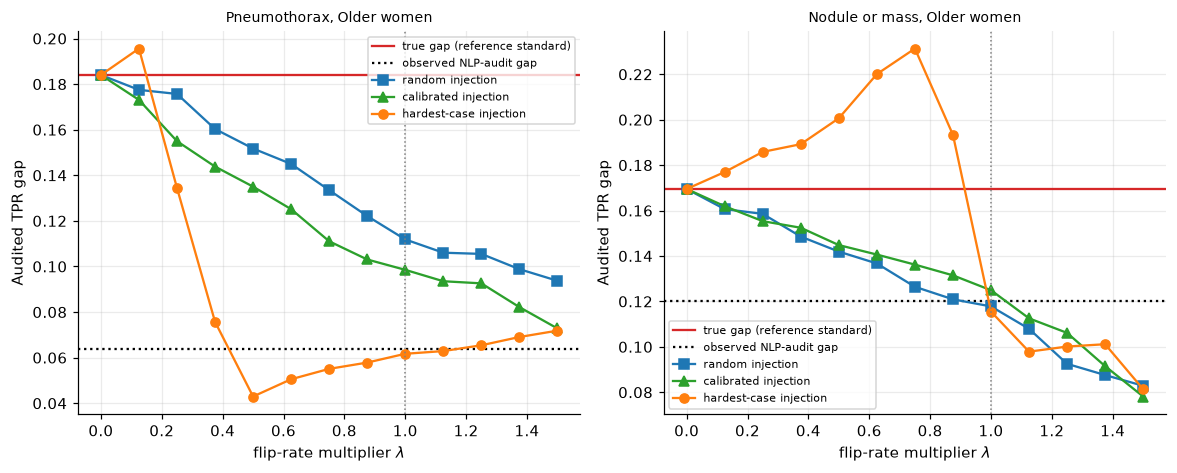

In [13]:
# 3e. Dose-response in the two cells with the largest observed concealment (original selection), with the calibrated arm
conceal = DEC[DEC["phantom_observed"] > 0].sort_values("phantom_observed", ascending=False)
sel = list(zip(conceal["finding"], conceal["axis"]))[:2] or CELLS_FA[:2]
lams = np.linspace(0, 1.5, 13)
fig, axs = plt.subplots(1, len(sel), figsize=(5.4 * len(sel), 4.4), squeeze=False); DR = []
for k, (f0, ax0) in enumerate(sel):
    base = phantom_decomposition(EVAL, f0, ax0, lam=0.0, n_mc=max(60, CFG.n_inject_mc // 2))
    c = cell_arrays(f0, ax0); gcc, gid, gca = [], [], []
    for lam in lams:
        d = phantom_decomposition(EVAL, f0, ax0, lam=lam, n_mc=max(60, CFG.n_inject_mc // 2))
        rr = pc.injection_cell(c["y_adj"], c["y_nlp"], c["score"], c["groups"], c["thr"], n_mc=max(60, CFG.n_inject_mc // 2), seed=1, lam=lam)
        gcc.append(d["gap_classcond"]); gid.append(d["gap_instancedep"]); gca.append(rr["clean_gap"] - rr["conceal_calibrated"])
        DR.append({"finding": f0, "axis": ax0, "lambda": lam, "gap_random": d["gap_classcond"], "gap_hardest": d["gap_instancedep"],
                   "gap_calibrated": gca[-1], "true_gap": base["clean_gap"], "nlp_gap": base["observed_nlp_gap"]})
    a = axs[0][k]
    a.axhline(base["clean_gap"], color="C3", lw=1.5, label="true gap (reference standard)")
    a.axhline(base["observed_nlp_gap"], color="k", ls=":", lw=1.5, label="observed NLP-audit gap")
    a.plot(lams, gcc, marker="s", color="C0", label="random injection")
    a.plot(lams, gca, marker="^", color="C2", label="calibrated injection")
    a.plot(lams, gid, marker="o", color="C1", label="hardest-case injection")
    a.axvline(1.0, color="grey", ls=":", lw=1); a.set_xlabel(r"flip-rate multiplier $\lambda$"); a.set_ylabel("Audited TPR gap")
    a.set_title(f"{f0}, {pc.AXIS_LABELS[ax0]}", fontsize=9); a.legend(fontsize=7)
pd.DataFrame(DR).to_csv(CFG.tab_dir / "table_dose_response.csv", index=False)
plt.savefig(CFG.fig_dir / "fig9_mechanism.png", bbox_inches="tight"); plt.show()

---
## 4. Threshold-based mitigation

Unchanged procedure (25 random patient-level calibration/test splits, equal-opportunity thresholds set on reference-standard or NLP labels of the calibration half, gap measured on the test half against the reference standard), now with the 2.5th and 97.5th percentiles across splits.

,finding,axis,gap_global,gap_global_p2.5,gap_global_p97.5,gap_clean_remedy,gap_clean_p2.5,gap_clean_p97.5,gap_noisy_remedy,gap_noisy_p2.5,gap_noisy_p97.5,remedy_balanced_acc,n_rep_used,underpowered
0,Airspace opacity,sex,0.029,0.000,0.052,0.052,0.006,0.108,0.041,0.002,0.111,0.746,25,False
1,Airspace opacity,elderly_women,0.031,0.001,0.062,0.041,0.003,0.113,0.117,0.014,0.230,0.749,25,False
2,Pneumothorax,sex,0.192,0.063,0.325,0.131,0.010,0.294,0.122,0.010,0.285,0.650,25,False
3,Pneumothorax,elderly_women,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,True
4,Nodule or mass,sex,0.060,0.009,0.125,0.111,0.017,0.257,0.089,0.011,0.231,0.633,25,False
5,Nodule or mass,elderly_women,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,True


Adequately powered cells: 4 of 6; median gap single threshold 0.046, reference-calibrated 0.082, NLP-calibrated 0.103


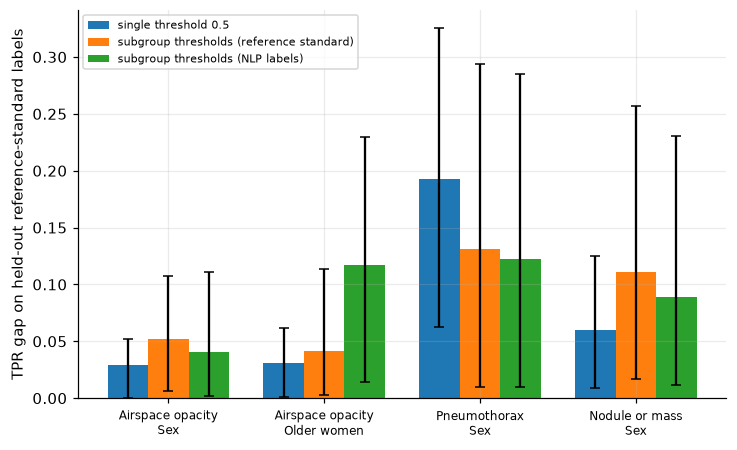

In [14]:
def find_threshold_for_tpr(y, p, target):
    y = np.asarray(y).astype(int); p = np.asarray(p, float); pos = p[y == 1]
    return 0.5 if len(pos) == 0 else float(np.quantile(pos, np.clip(1.0 - target, 0.0, 1.0)))
def _gap_at(df, axis, sc, ylab, thr_map):
    tp = {}
    for g, s in df.groupby(axis):
        y = s[ylab].astype(float).values; v = ~np.isnan(y); y = y[v].astype(int); p = s[sc].values[v]
        tp[str(g)] = pc.tpr_fpr(y, (p >= thr_map.get(str(g), 0.5)).astype(int))[0]
    return pc.gap_from_groups(tp)
def _util(df, axis, sc, ylab, thr_map):
    y = df[ylab].astype(int).values; p = df[sc].values; g = df[axis].astype(str).values
    yhat = np.array([pi >= thr_map.get(gi, 0.5) for pi, gi in zip(p, g)]).astype(int); t, f = pc.tpr_fpr(y, yhat)
    return 0.5 * ((0 if np.isnan(t) else t) + (1 - (0 if np.isnan(f) else f)))
def remedy_experiment(finding, axis, n_rep=25, min_pos=20):
    sc, ad, nl = "score_" + finding, "adj_" + finding, "nlp_" + finding
    sub = EVAL[EVAL[ad].notna()].reset_index(drop=True)
    pos_by_g = sub.groupby(axis)[ad].sum()
    base = {"finding": finding, "axis": axis, "underpowered": True, "n_rep_used": 0}
    if pos_by_g.min() < 2 * min_pos: return base
    pats = sub["patient_id"].unique(); G, C, N, B = [], [], [], []
    for rep in range(n_rep):
        r = np.random.default_rng(CFG.random_seed + rep); pp = pats.copy(); r.shuffle(pp)
        calp = set(pp[: int(0.5 * len(pp))]); cal = sub[sub["patient_id"].isin(calp)]; test = sub[~sub["patient_id"].isin(calp)]
        if cal[axis].nunique() < 2 or test[axis].nunique() < 2 or len(test) < 40: continue
        if cal.groupby(axis)[ad].sum().min() < min_pos: continue
        tg = pc.tpr_fpr(cal[ad].astype(int).values, (cal[sc].values >= 0.5).astype(int))[0]; target = tg if not np.isnan(tg) else 0.7
        thr_g = {str(g): 0.5 for g in test[axis].unique()}
        thr_c = {str(g): find_threshold_for_tpr(gr[ad].astype(int).values, gr[sc].values, target) for g, gr in cal.groupby(axis)}
        thr_n = {str(g): find_threshold_for_tpr(gr[nl].astype(int).values, gr[sc].values, target) for g, gr in cal.groupby(axis)}
        G.append(_gap_at(test, axis, sc, ad, thr_g)); C.append(_gap_at(test, axis, sc, ad, thr_c)); N.append(_gap_at(test, axis, sc, ad, thr_n))
        B.append(_util(test, axis, sc, ad, thr_c))
    if not C: return base
    q = lambda v, x: float(np.nanpercentile(v, x))
    return {"finding": finding, "axis": axis, "gap_global": np.nanmean(G), "gap_global_p2.5": q(G, 2.5), "gap_global_p97.5": q(G, 97.5),
            "gap_clean_remedy": np.nanmean(C), "gap_clean_p2.5": q(C, 2.5), "gap_clean_p97.5": q(C, 97.5),
            "gap_noisy_remedy": np.nanmean(N), "gap_noisy_p2.5": q(N, 2.5), "gap_noisy_p97.5": q(N, 97.5),
            "remedy_balanced_acc": np.nanmean(B), "n_rep_used": len(C), "underpowered": False}
with TIMES.track("remedy"):
    REM = pd.DataFrame([remedy_experiment(f, ax) for f, ax in CELLS_FA])
REM.to_csv(CFG.tab_dir / "table11_remedy.csv", index=False); display(REM.round(3))
well = REM[~REM["underpowered"]]
if len(well):
    print(f"Adequately powered cells: {len(well)} of {len(REM)}; median gap single threshold {well['gap_global'].median():.3f}, "
          f"reference-calibrated {well['gap_clean_remedy'].median():.3f}, NLP-calibrated {well['gap_noisy_remedy'].median():.3f}")
    lab = well["finding"] + "\n" + well["axis"].map(pc.AXIS_LABELS); x = np.arange(len(well)); w = 0.26
    fig, ax = plt.subplots(figsize=(max(6, 1.7 * len(well)), 4.2))
    for off, col, lo, hi, nm in [(-w, "gap_global", "gap_global_p2.5", "gap_global_p97.5", "single threshold 0.5"),
                                 (0, "gap_clean_remedy", "gap_clean_p2.5", "gap_clean_p97.5", "subgroup thresholds (reference standard)"),
                                 (w, "gap_noisy_remedy", "gap_noisy_p2.5", "gap_noisy_p97.5", "subgroup thresholds (NLP labels)")]:
        ax.bar(x + off, well[col], w, yerr=[(well[col] - well[lo]).clip(lower=0), (well[hi] - well[col]).clip(lower=0)], capsize=3, label=nm)
    ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel("TPR gap on held-out reference-standard labels")
    ax.legend(fontsize=7); plt.savefig(CFG.fig_dir / "fig10_remedy.png", bbox_inches="tight"); plt.show()

---
## 5. Robustness to the older-women age cut-off (55, 60, 65 years), now with the calibrated arm

In [15]:
rows = []
for cut in (55, 60, 65):
    ev = EVAL.copy(); ev["ew_var"] = ((ev["sex"] == "F") & (ev["age"] > cut)).map({True: "F>cut", False: "other"})
    for f in NLP_FINDINGS:
        sub = ev[ev["adj_" + f].notna()]
        MEASURED_NOISE[(f, "ew_var")] = measure_group_noise(ev, f, "ew_var")
        d = phantom_decomposition(ev, f, "ew_var", lam=1.0, n_mc=max(40, CFG.n_inject_mc // 2))
        if d is None: continue
        c = pc.injection_cell(sub["adj_" + f].astype(int).values, sub["nlp_" + f].astype(int).values, sub["score_" + f].values,
                              sub["ew_var"].values, MODELS[P]["thresholds"][f], n_mc=max(40, CFG.n_inject_mc // 2), seed=0)
        rows.append({"finding": f, "elderly_cut": cut, "n_older_women": int((sub["ew_var"] == "F>cut").sum()),
                     "phantom_observed": d["phantom_observed"], "phantom_classcond": d["phantom_classcond"],
                     "phantom_calibrated": c["conceal_calibrated"], "phantom_instancedep": d["phantom_instancedep"],
                     "instancedep_dominates": bool(d["phantom_instancedep"] > d["phantom_classcond"]),
                     "calibrated_exceeds_random": bool(c["conceal_calibrated"] > d["phantom_classcond"])})
ROB = pd.DataFrame(rows); ROB.to_csv(CFG.tab_dir / "table12_robustness.csv", index=False); display(ROB.round(3))
print(f"Hardest-case > random in {int(ROB['instancedep_dominates'].sum())} of {len(ROB)} cells; "
      f"calibrated > random in {int(ROB['calibrated_exceeds_random'].sum())} of {len(ROB)}")

,finding,elderly_cut,n_older_women,phantom_observed,phantom_classcond,phantom_calibrated,phantom_instancedep,instancedep_dominates,calibrated_exceeds_random
0,Airspace opacity,55,564,0.013,-0.016,-0.006,-0.011,True,True
1,Pneumothorax,55,564,0.075,0.043,0.042,0.085,True,False
2,Nodule or mass,55,564,-0.130,-0.014,-0.016,-0.023,False,False
3,Airspace opacity,60,361,-0.039,-0.021,-0.026,-0.040,False,False
4,Pneumothorax,60,361,0.120,0.072,0.091,0.122,True,True
5,Nodule or mass,60,361,0.049,0.052,0.051,0.054,True,False
6,Airspace opacity,65,209,-0.035,-0.050,-0.054,-0.060,False,False
7,Pneumothorax,65,209,0.025,0.046,0.042,0.058,True,False
8,Nodule or mass,65,209,0.061,0.003,-0.009,-0.061,False,False


Hardest-case > random in 5 of 9 cells; calibrated > random in 2 of 9


---
## 6. Results text generated from the tables

The paragraph below is assembled from the files on disk so the wording cannot drift from the numbers. Its phrasing follows reviewer 4: the instance dependence is reported as an association in models trained on NLP labels (Part 4 extends it), the subgroup concealment as suggestive, and the injection as a mechanistic illustration.

In [16]:
L = ["## Results (generated, revision 2)\n"]
idp = ID[ID["score_source"] == P]
npos = int((idp["rank_biserial"] > 0).sum())
L.append(f"Among reference-standard positives, models trained on NLP labels scored NLP-missed images lower than NLP-caught images for "
         f"{'every finding' if npos == len(idp) else f'{npos} of {len(idp)} findings'} on the primary backbone (rank-biserial r "
         f"{idp['rank_biserial'].min():.2f} to {idp['rank_biserial'].max():.2f}; patient-level bootstrap intervals "
         f"{', '.join(f'{a:.2f} to {b:.2f}' for a, b in zip(idp['r_lo_patient'], idp['r_hi_patient']))}). "
         f"Across {len(ID)} backbone-by-finding tests, {int((ID['p_patient_boot_bh'] < 0.05).sum())} remained significant after "
         f"Benjamini-Hochberg adjustment with the patient-level bootstrap, {int((ID['p_wcr_bh'] < 0.05).sum())} with within-cluster resampling and "
         f"{int((ID['p_gee_adj_bh'] < 0.05).sum())} in GEE models adjusted for sex, age band and projection "
         f"(image-level Mann-Whitney: {int((ID['p_image_mwu_bh'] < 0.05).sum())}).\n")
if T2 is not None:
    mp = T2["p_bh_patient"].min()
    L.append(f"On identical images, the reference-standard gap exceeded the NLP gap in {int((T2['regime_diff'] > 0).sum())} of {len(T2)} comparisons "
             f"(median difference {T2['regime_diff'].median():.3f}). With patient-level resampling, "
             + ("no comparison remained significant after Benjamini-Hochberg adjustment " if mp >= 0.05 else
                f"{int((T2['p_bh_patient'] < 0.05).sum())} comparison(s) remained significant after Benjamini-Hochberg adjustment ")
             + f"(smallest adjusted p {mp:.2f}).\n")
r = BOOTSUM.sort_values("phantom_observed", ascending=False).iloc[0]
L.append(f"The largest observed concealment was for {r['finding'].lower()} on the {pc.AXIS_LABELS[r['axis']].lower()} axis "
         f"({r['phantom_observed']:.3f}; 95% patient-level interval {r['observed_lo']:.3f} to {r['observed_hi']:.3f}). At the measured flip rates, "
         f"random injection produced {r['phantom_classcond']:.3f}, calibrated injection {r['phantom_calibrated']:.3f} and hardest-case injection "
         f"{r['phantom_instancedep']:.3f} (patient-level intervals {r['random_lo']:.3f} to {r['random_hi']:.3f}, {r['calibrated_lo']:.3f} to "
         f"{r['calibrated_hi']:.3f} and {r['hardest_lo']:.3f} to {r['hardest_hi']:.3f}). The simulation shows what each kind of noise at these rates "
         f"would do to the audit; agreement in one cell does not show that the mechanism caused the observed gap.\n")
pool = XFSUM[XFSUM["axis"] == "pooled"].iloc[0]
L.append(f"When flip rates were estimated on half of the patients and concealment was predicted in the other half ({int(pool['n_splits'])} split-cells), "
         f"mean absolute prediction errors were {pool['random_MAE']:.3f} (random), {pool['calibrated_MAE']:.3f} (calibrated) and {pool['hardest_MAE']:.3f} "
         f"(hardest-case); the calibrated arm was closer than the random arm in {100 * pool['P(calibrated closer than random)']:.0f}% of split-cells.\n")
if len(well):
    g0, gc, gn = well["gap_global"].median(), well["gap_clean_remedy"].median(), well["gap_noisy_remedy"].median()
    L.append(f"In the {len(well)} adequately powered cells, subgroup-specific thresholds {'reduced' if gc < g0 else 'did not reduce'} the median held-out gap "
             f"when set on reference-standard labels ({g0:.3f} to {gc:.3f}) and {'reduced' if gn < g0 else 'did not reduce'} it when set on NLP labels ({gn:.3f}).\n")
RESULTS = "\n".join(L); (CFG.tab_dir / "RESULTS_phantom_fairness.md").write_text(RESULTS, encoding="utf-8"); print(RESULTS)

## Results (generated, revision 2)

Among reference-standard positives, models trained on NLP labels scored NLP-missed images lower than NLP-caught images for every finding on the primary backbone (rank-biserial r 0.17 to 0.24; patient-level bootstrap intervals 0.15 to 0.26, 0.03 to 0.30, 0.13 to 0.35). Across 12 backbone-by-finding tests, 12 remained significant after Benjamini-Hochberg adjustment with the patient-level bootstrap, 8 with within-cluster resampling and 8 in GEE models adjusted for sex, age band and projection (image-level Mann-Whitney: 12).

The largest observed concealment was for pneumothorax on the older women axis (0.120; 95% patient-level interval -0.059 to 0.243). At the measured flip rates, random injection produced 0.077, calibrated injection 0.087 and hardest-case injection 0.124 (patient-level intervals -0.055 to 0.149, -0.040 to 0.176 and -0.034 to 0.224). The simulation shows what each kind of noise at these rates would do to the audit; agreement in one cell

---
## 7. How to read these results

**What is observed.** The NLP labels miss a large share of reference-standard positives at rates that differ between subgroups (Part 2), and in models trained on those labels the missed positives receive lower scores. Whether that association survives patient-level inference, and whether it also holds for scores that never saw the NLP labels (Part 4), is what the tables above and in Part 4 report.

**What the simulation shows.** Injection is a mechanistic illustration: it shows what concealment noise of the measured size and kind *can* produce. The calibrated arm is the realistic case, the hardest-case arm an upper limit. Agreement between an arm and the observed concealment in one cell is not evidence that the mechanism caused that cell's gap, particularly when the observed gap difference has an interval that includes zero.

**What generalises.** The sample-split analysis is the closest this data set allows to an out-of-sample test: flip rates estimated on one half of the patients are used to predict concealment in the other half. Its prediction errors, not the in-sample agreement, are the fair measure of how well each noise model explains the data.

**Implication for practice.** A fairness audit that uses only automatically extracted labels cannot see the part of the disparity hidden by instance-dependent misses. How large an adjudicated reference set must be to *size* a disparity is estimated in Part 4 rather than asserted.

---
## 8. Provenance

In [17]:
tabs = sorted(CFG.tab_dir.glob("table1*.csv")) + sorted(CFG.tab_dir.glob("table8*.csv"))
prov = {"part": "3 (revision 2)", "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "primary_backbone": P,
        "backbones": list(EVALS.keys()), "n_eval": len(EVAL), "n_bootstrap": CFG.n_bootstrap, "n_wcr": CFG.n_wcr,
        "n_inject_mc": CFG.n_inject_mc, "n_inject_boot": CFG.n_inject_boot, "n_crossfit_splits": CFG.n_crossfit_splits,
        "seed": CFG.random_seed, "versions": VERSIONS,
        "tables": {p.name: pc.sha256_file(p) for p in tabs},
        "figures": {p.name: pc.sha256_file(p) for p in sorted(CFG.fig_dir.glob("fig*.png"))},
        "results_doc": pc.sha256_file(CFG.tab_dir / "RESULTS_phantom_fairness.md")}
pc.write_json(CFG.prov_dir / "provenance_part3.json", prov)
print("Part 3 provenance written:", len(prov["tables"]), "tables,", len(prov["figures"]), "figures")

Part 3 provenance written: 22 tables, 7 figures
